How many years do you want to simulate? 30
How much kelp would you like to start with? Default is 30.0 30
How many urchins do you want to start with? Maximum 100,000 10000
How effect are urchins at grazing? Default is 0.75 .75
How effective are your divers? Default is 0.015, or 1.5% remaining urchins annually 0.015
How many volunteer divers? Enter a whole number:  3
Turn on debug output? (y/n):  y



Modeling 3 volunteer divers.
Assumed annual removal: 4.5%
Starting sea urchin population: 10,000
Sea urchin carrying capacity: 100,000
Population values are hypothetical estimates, not field measurements.

Debug output: No diver removal
Year  1 | Kelp index:  39.39 | Urchin population: 9,853 | Urchins removed: 0
Year  2 | Kelp index:  51.61 | Urchin population: 9,725 | Urchins removed: 0
Year  3 | Kelp index:  67.43 | Urchin population: 9,619 | Urchins removed: 0
Year  4 | Kelp index:  87.72 | Urchin population: 9,541 | Urchins removed: 0
Year  5 | Kelp index: 113.45 | Urchin population: 9,497 | Urchins removed: 0
Year  6 | Kelp index: 145.60 | Urchin population: 9,495 | Urchins removed: 0
Year  7 | Kelp index: 184.99 | Urchin population: 9,544 | Urchins removed: 0
Year  8 | Kelp index: 232.06 | Urchin population: 9,653 | Urchins removed: 0
Year  9 | Kelp index: 286.54 | Urchin population: 9,835 | Urchins removed: 0
Year 10 | Kelp index: 347.18 | Urchin population: 10,100 | Urchins re

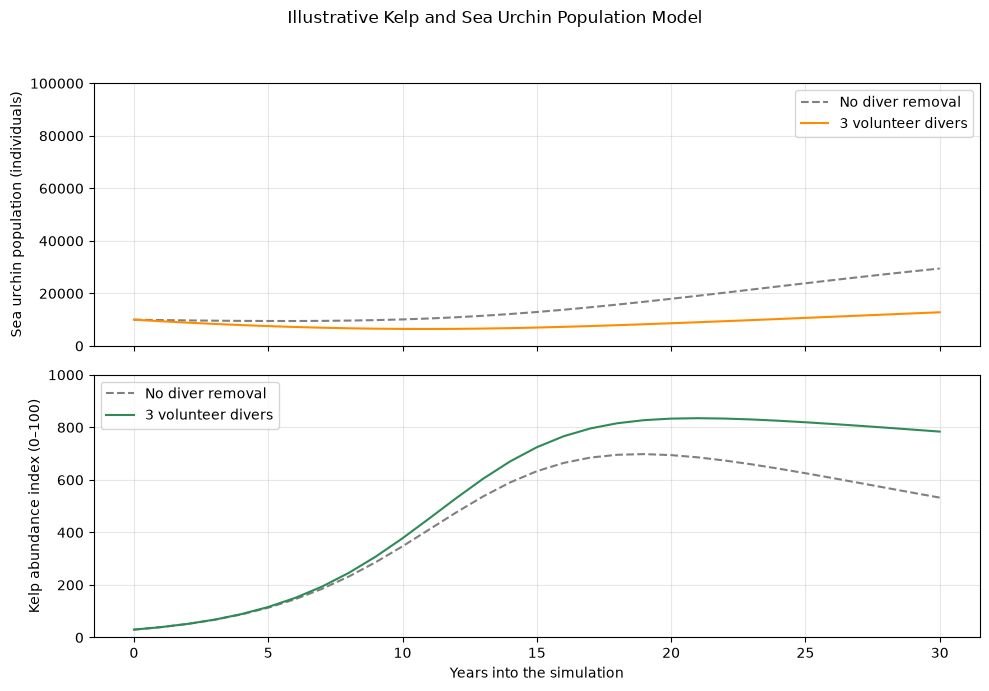

In [1]:

# Lets you set model options with arguments when running a script.
import argparse

# Lets the program draw and save graphs.
import matplotlib.pyplot as plt


# Sets how many years the model will simulate.
YEARS = int(input("How many years do you want to simulate?"))

# Sets the maximum kelp abundance index.
KELP_CAPACITY = 1000.0

# Sets the maximum number of sea urchins the area can support.
URCHIN_CAPACITY = 100000

# Sets the initial kelp abundance index.
STARTING_KELP = float(input("How much kelp would you like to start with? Default is 30.0"))

# Sets the initial population of sea urchins.
STARTING_URCHINS = int(input("How many urchins do you want to start with? Maximum 100,000"))

# Controls how quickly kelp grows when space is available.
KELP_GROWTH_RATE = 0.40

# Controls how quickly sea urchins reproduce when food is available.
URCHIN_GROWTH_RATE = 0.15

# Represents the natural annual mortality rate of sea urchins.
URCHIN_DEATH_RATE = 0.02

# Controls how strongly sea urchin grazing reduces kelp.
GRAZING_RATE = float(input("How effect are urchins at grazing? Default is 0.75"))

# Assumes each volunteer diver removes 1.5% of the remaining urchins annually.
REMOVAL_PER_DIVER = float(input("How effective are your divers? Default is 0.015, or 1.5% remaining urchins annually"))

# Limits the total annual removal rate to 60%.
MAX_REMOVAL_FRACTION = 0.60


# Runs a simulation with or without volunteer diver removal.
def simulate(removal_fraction, scenario_name, debug):

    # Sets kelp to its starting abundance index.
    kelp = STARTING_KELP

    # Sets sea urchins to their starting population.
    urchins = STARTING_URCHINS

    # Stores the starting year.
    years = [0]

    # Stores the starting kelp abundance.
    kelp_history = [kelp]

    # Stores the starting sea urchin population.
    urchin_history = [urchins]

    # Checks whether debug output was requested.
    if debug:

        # Labels the simulation being displayed.
        print(f"\nDebug output: {scenario_name}")

    # Repeats the simulation once for each year.
    for year in range(1, YEARS + 1):

        # Calculates kelp growth using logistic growth.
        kelp_growth = KELP_GROWTH_RATE * kelp * (1 - kelp / KELP_CAPACITY)

        # Calculates kelp lost from sea urchin grazing.
        grazing_loss = GRAZING_RATE * kelp * (urchins / URCHIN_CAPACITY)

        # Updates kelp after growth and grazing.
        kelp = kelp + kelp_growth - grazing_loss

        # Keeps kelp between zero and its maximum abundance index.
        kelp = max(0.0, min(KELP_CAPACITY, kelp))

        # Calculates how much kelp is available as food.
        food_available = kelp / KELP_CAPACITY

        # Estimates sea urchin births based on food availability and population size.
        urchin_births = URCHIN_GROWTH_RATE * urchins * food_available * (1 - urchins / URCHIN_CAPACITY)

        # Estimates the number of sea urchins dying naturally.
        natural_deaths = URCHIN_DEATH_RATE * urchins

        # Updates the sea urchin population before volunteer removal.
        urchins = urchins + urchin_births - natural_deaths

        # Keeps the population between zero and its carrying capacity.
        urchins = max(0.0, min(URCHIN_CAPACITY, urchins))

        # Calculates the number of sea urchins removed by divers.
        urchins_removed = urchins * removal_fraction

        # Subtracts the removed sea urchins from the population.
        urchins = urchins - urchins_removed

        # Saves the current year.
        years.append(year)

        # Saves the current kelp abundance.
        kelp_history.append(kelp)

        # Saves the current sea urchin population.
        urchin_history.append(urchins)

        # Checks whether debug output is enabled.
        if debug:

            # Prints the estimated population and kelp abundance each year.
            print(
                f"Year {year:2d} | "
                f"Kelp index: {kelp:6.2f} | "
                f"Urchin population: {urchins:,.0f} | "
                f"Urchins removed: {urchins_removed:,.0f}"
            )

    # Returns the simulation results for graphing.
    return years, kelp_history, urchin_history


# Runs the program, collects user input, and creates graphs.
def main():

    # Creates command-line options.
    parser = argparse.ArgumentParser(description="Model sea urchin populations and kelp recovery with volunteer divers.")

    # Adds an optional argument for the number of volunteer divers.
    parser.add_argument("--divers", type=int, default=None, help="Number of volunteer divers.")

    # Adds an optional argument for debug output.
    parser.add_argument("--debug", action="store_true", help="Print yearly model values.")

    # Reads arguments while ignoring extra Jupyter kernel arguments.
    args, _ = parser.parse_known_args()

    # Checks whether the number of divers was supplied.
    if args.divers is None:

        # Continues asking until a valid number is entered.
        while True:

            # Attempts to read the user's input.
            try:

                # Asks how many volunteer divers are participating.
                divers = int(input("How many volunteer divers? Enter a whole number: "))

                # Checks whether the number is negative.
                if divers < 0:

                    # Explains that negative numbers are not allowed.
                    print("Please enter zero or a positive number.")

                    # Repeats the input prompt.
                    continue

                # Exits the loop when a valid number is entered.
                break

            # Handles invalid entries.
            except ValueError:

                # Explains the expected input.
                print("Please enter a whole number, such as 5.")

    # Uses the diver number supplied through command-line arguments.
    else:

        # Stores the number of divers.
        divers = args.divers

        # Checks for negative values.
        if divers < 0:

            # Stops the program if the number is invalid.
            parser.error("The number of divers cannot be negative.")

    # Checks whether debug mode was enabled through arguments.
    debug = args.debug

    # Asks about debug mode if it was not already enabled.
    if not debug:

        # Prompts the user to enable or disable debug output.
        debug_answer = input("Turn on debug output? (y/n): ").strip().lower()

        # Enables debug mode if the user enters yes.
        debug = debug_answer in ("y", "yes")

    # Calculates the annual removal fraction based on volunteer divers.
    removal_fraction = min(divers * REMOVAL_PER_DIVER, MAX_REMOVAL_FRACTION)

    # Displays the number of participating divers.
    print(f"\nModeling {divers} volunteer divers.")

    # Displays the estimated annual removal percentage.
    print(f"Assumed annual removal: {removal_fraction * 100:.1f}%")

    # Displays the starting sea urchin population.
    print(f"Starting sea urchin population: {STARTING_URCHINS:,}")

    # Displays the maximum carrying capacity.
    print(f"Sea urchin carrying capacity: {URCHIN_CAPACITY:,}")

    # Explains that the population assumptions are hypothetical.
    print("Population values are hypothetical estimates, not field measurements.")

    # Runs the simulation without volunteer diver removal.
    years, kelp_baseline, urchin_baseline = simulate(0.0, "No diver removal", debug)

    # Runs the simulation with volunteer diver removal.
    _, kelp_with_divers, urchin_with_divers = simulate(removal_fraction, f"{divers} volunteer divers", debug)

    # Creates two graph panels that share the same horizontal axis.
    figure, (urchin_axis, kelp_axis) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    # Draws the sea urchin population without diver removal.
    urchin_axis.plot(years, urchin_baseline, linestyle="--", color="gray", label="No diver removal")

    # Draws the sea urchin population with diver removal.
    urchin_axis.plot(years, urchin_with_divers, color="darkorange", label=f"{divers} volunteer divers")

    # Labels the vertical axis with the number of individual sea urchins.
    urchin_axis.set_ylabel("Sea urchin population (individuals)")

    # Sets the graph limits based on the carrying capacity.
    urchin_axis.set_ylim(0, URCHIN_CAPACITY)

    # Displays the graph legend.
    urchin_axis.legend()

    # Adds a light grid to the graph.
    urchin_axis.grid(True, alpha=0.3)

    # Draws kelp abundance without volunteer diver removal.
    kelp_axis.plot(years, kelp_baseline, linestyle="--", color="gray", label="No diver removal")

    # Draws kelp abundance with volunteer diver removal.
    kelp_axis.plot(years, kelp_with_divers, color="seagreen", label=f"{divers} volunteer divers")

    # Labels the horizontal axis.
    kelp_axis.set_xlabel("Years into the simulation")

    # Labels the vertical axis for kelp abundance.
    kelp_axis.set_ylabel("Kelp abundance index (0–100)")

    # Sets the limits for kelp abundance.
    kelp_axis.set_ylim(0, KELP_CAPACITY)

    # Displays the kelp graph legend.
    kelp_axis.legend()

    # Adds a light grid to the kelp graph.
    kelp_axis.grid(True, alpha=0.3)

    # Adds a title to the figure.
    figure.suptitle("Illustrative Kelp and Sea Urchin Population Model")

    # Adjusts spacing between the graphs.
    figure.tight_layout(rect=[0, 0, 1, 0.95])

    # Saves the graphs as an image.
    figure.savefig("kelp_urchin_population_model.png", dpi=200)

    # Displays the graphs.
    plt.show()


# Checks whether the script is being run directly.
if __name__ == "__main__":

    # Starts the program.
    main()